In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [2]:
# Contoh data penjualan bulanan
data = {
    'month': pd.date_range(start='2022-01-01', periods=24, freq='ME'),
    'sales': [200, 220, 215, 230, 250, 265, 280, 300, 320, 310, 330, 350,
              370, 390, 400, 420, 440, 460, 480, 490, 500, 520, 540, 560]
}
df = pd.DataFrame(data)
df.set_index('month', inplace=True)
df

,sales
month,
2022-01-31,200
2022-02-28,220
2022-03-31,215
2022-04-30,230
2022-05-31,250
2022-06-30,265
2022-07-31,280
2022-08-31,300
2022-09-30,320


FORECASTING MACHINE LEARNING

In [3]:
def create_lag_features(series, window):
    df_lag = pd.DataFrame()
    for i in range(1, window + 1):
        df_lag[f'lag_{i}'] = series.shift(i)
    df_lag['target'] = series.values
    df_lag.dropna(inplace=True)
    return df_lag

In [4]:
window = 3
df_ml = create_lag_features(df['sales'], window)
df_ml

,lag_1,lag_2,lag_3,target
month,,,,
2022-04-30,215.0,220.0,200.0,230
2022-05-31,230.0,215.0,220.0,250
2022-06-30,250.0,230.0,215.0,265
2022-07-31,265.0,250.0,230.0,280
2022-08-31,280.0,265.0,250.0,300
2022-09-30,300.0,280.0,265.0,320
2022-10-31,320.0,300.0,280.0,310
2022-11-30,310.0,320.0,300.0,330
2022-12-31,330.0,310.0,320.0,350


In [5]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

x = df_ml.drop('target', axis=1)
y = df_ml[['target']]

# scale = MinMaxScaler()
# scale_x = scale.fit_transform(x)
# scale_y = scale.fit_transform(y).ravel()

# error : 
# memakai satu objek scaler (scale) untuk dua hal berbeda:
# scale_x (3 fitur: lag_1, lag_2, lag_3)
# scale_y (1 fitur: target)
# Ini menyebabkan MinMaxScaler hanya menyimpan skala dari yang terakhir, 
# yaitu target (1 fitur), sehingga saat pakai transform() untuk array 
# dengan 3 kolom, error muncul.

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scale_x = scaler_x.fit_transform(x)
scale_y = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(scale_x, scale_y, test_size=0.2, random_state=42)


In [6]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

RandomForestRegressor(random_state=42)

In [7]:
y_pred = model.predict(x_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE (Test Set):", rmse)

RMSE (Test Set): 0.06718353355473264


In [8]:
# --- 8. Forecast 2 bulan ke depan ---
n_future = 2
last_values = df['sales'].values[-window:]  # ambil 3 data terakhir (untuk lag)

forecast_scaled = []

for _ in range(n_future):
    input_vals = np.array(last_values[-window:]).reshape(1, -1)
    input_df = pd.DataFrame(input_vals, columns=x.columns)  
    input_scaled = scaler_x.transform(input_df)
    pred_scaled = model.predict(input_scaled)[0]  
    forecast_scaled.append(pred_scaled)

    # Konversi prediksi kembali ke skala asli, lalu tambahkan untuk langkah berikutnya
    pred_unscaled = scaler_y.inverse_transform([[pred_scaled]])[0][0]
    last_values = np.append(last_values, pred_unscaled)


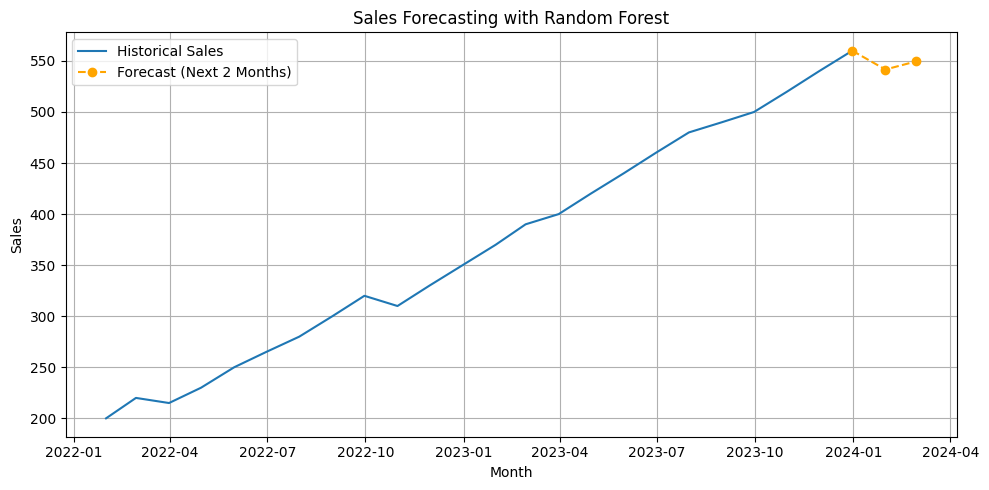

In [9]:
# Konversi seluruh hasil forecast ke skala asli
forecast_unscaled = [scaler_y.inverse_transform([[val]])[0][0] for val in forecast_scaled]

# Buat index tanggal untuk hasil forecast
future_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=n_future, freq='ME')

# Gabungkan titik terakhir dari histori ke awal forecast
joined_dates = [df.index[-1]] + list(future_dates)
joined_sales = [df['sales'].iloc[-1]] + forecast_unscaled

# --- 9. Visualisasi ---
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['sales'], label='Historical Sales')
plt.plot(joined_dates, joined_sales, label='Forecast (Next 2 Months)', linestyle='--', marker='o', color='orange')
plt.title('Sales Forecasting with Random Forest')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
print(f"prediksi harga berikutnya : {forecast_unscaled}")

prediksi harga berikutnya : [541.5999999999997, 549.5999999999999]


FORECASTING TIME SERIES

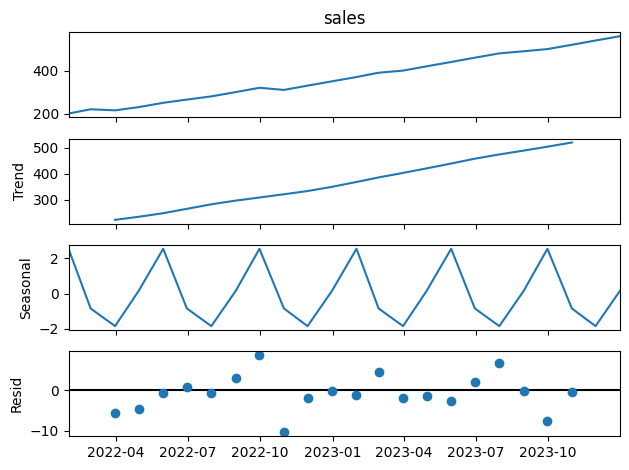

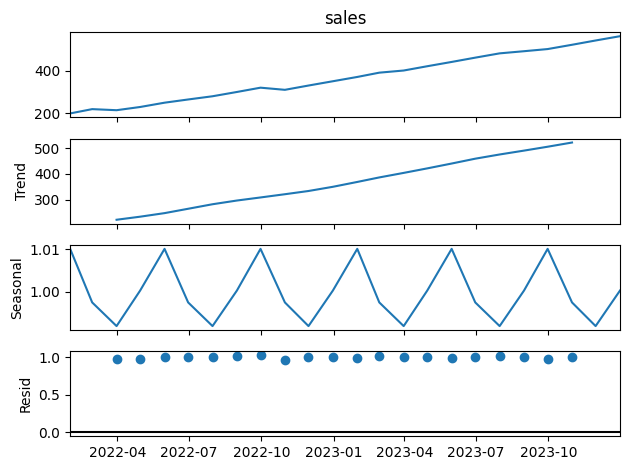

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose

result_add = seasonal_decompose(df["sales"], period=4, model="additive")
result_mul = seasonal_decompose(df["sales"], period=4, model="multiplicative")
result_add.plot()
result_mul.plot()
plt.show()

In [12]:
# moving average

mvg = df["sales"].reset_index()
mvg["Moving_avg"] = mvg["sales"].rolling(window=4).mean()
mvg[["sales", "Moving_avg"]]

,sales,Moving_avg
0,200,NaN
1,220,NaN
2,215,NaN
3,230,216.25
4,250,228.75
5,265,240.00
6,280,256.25
7,300,273.75
8,320,291.25
9,310,302.50


In [13]:
# 1. Salin data awal
sales_data = list(df["sales"].values)

# 2. Forecast 2 bulan ke depan
n_future = 2
window = 4
forecast_ma = []

for _ in range(n_future):
    if len(sales_data) < window:
        avg = np.mean(sales_data)
    else:
        avg = np.mean(sales_data[-window:])
    forecast_ma.append(avg)
    sales_data.append(avg)  # tambahkan prediksi untuk langkah selanjutnya

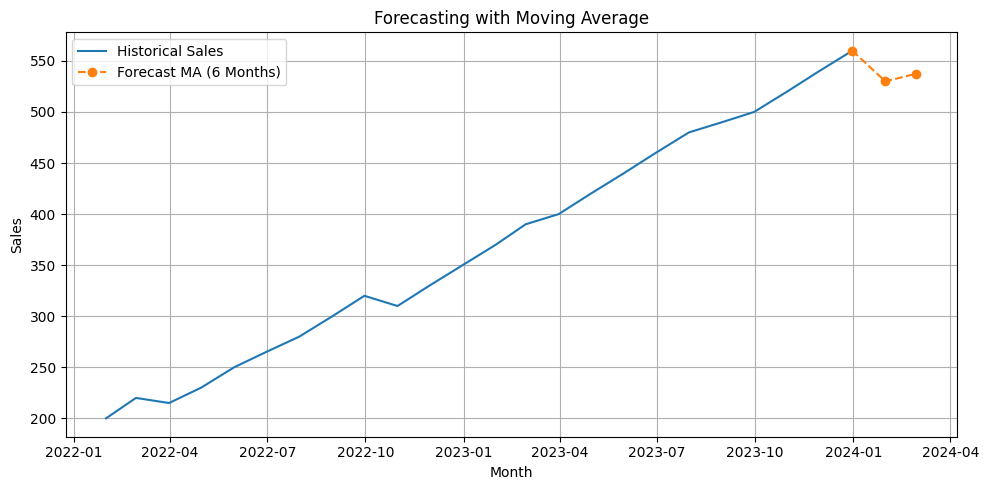

In [14]:
future_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=n_future, freq='ME')

joined_dates = [df.index[-1]] + list(future_dates)
joined_sales = [df['sales'].iloc[-1]] + forecast_ma

plt.figure(figsize=(10, 5))
plt.plot(df.index, df['sales'], label='Historical Sales')
plt.plot(joined_dates, joined_sales, label='Forecast MA (6 Months)', linestyle='--', marker='o')
plt.title('Forecasting with Moving Average')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
print(f"prediksi harga berikutnya : {forecast_ma}")

prediksi harga berikutnya : [530.0, 537.5]


In [16]:
# exponential smoothing

from statsmodels.tsa.holtwinters import ExponentialSmoothing

double = ExponentialSmoothing(df["sales"].values, trend="add", seasonal="add", seasonal_periods=4).fit()

day = 2
double_forecast = double.forecast(steps=day)

print(f"prediksi harga berikutnya : {double_forecast}")

prediksi harga berikutnya : [576.26951291 590.4361852 ]


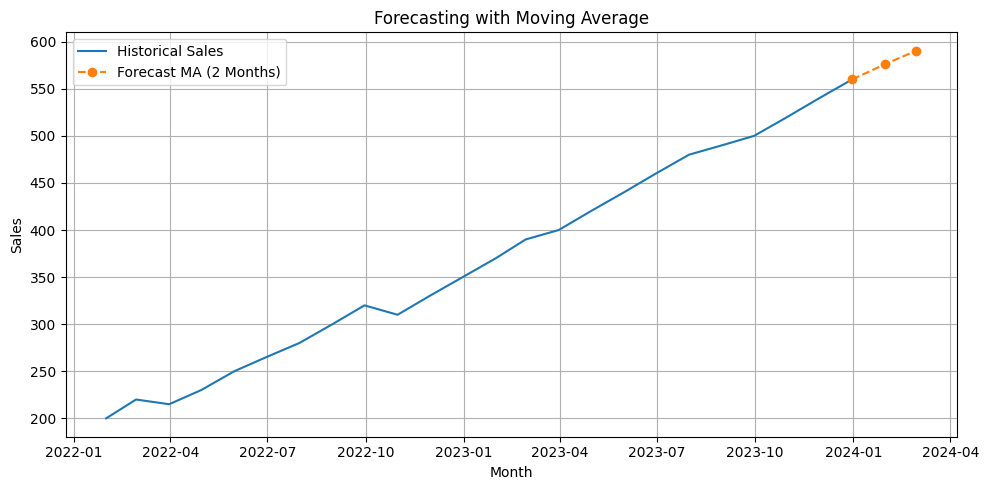

In [17]:
future_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=n_future, freq='ME')

joined_dates = [df.index[-1]] + list(future_dates)
joined_sales = [df['sales'].iloc[-1]] + list(double_forecast)

plt.figure(figsize=(10, 5))
plt.plot(df.index, df['sales'], label='Historical Sales')
plt.plot(joined_dates, joined_sales, label='Forecast MA (2 Months)', linestyle='--', marker='o')
plt.title('Forecasting with Moving Average')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            4     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  4.27058D+00    |proj g|=  2.38364D-02

At iterate    5    f=  3.43868D+00    |proj g|=  1.21410D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    4      8     19      1     0     0   9.628D-06   3.439D+00
  F =   3.4386767917070946     

CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL            


 This problem is unconstrained.


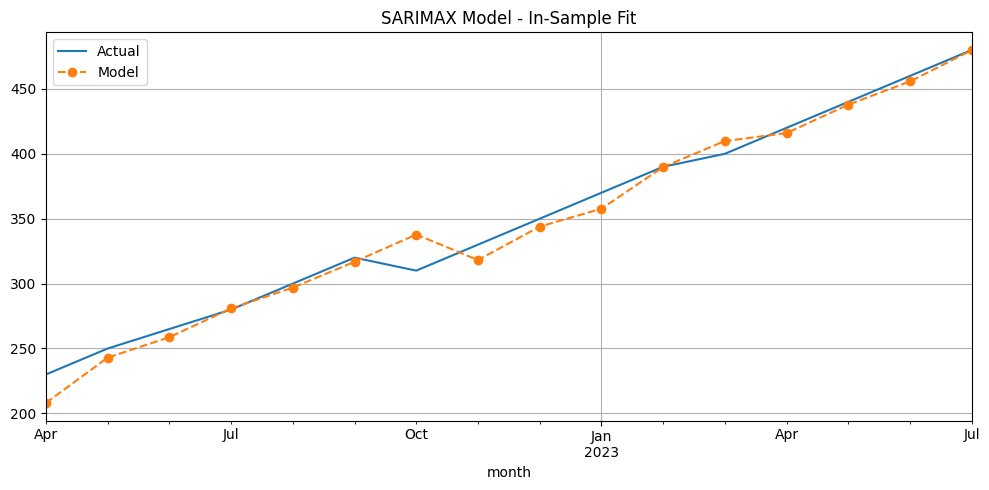

In [18]:
# SARIMAX

from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima.arima import auto_arima

# Split train-test
len_train = int(len(df_ml) * 0.8)
train = df_ml[:len_train]
test = df_ml[len_train:]

# Atur frekuensi index
train.index.freq = 'ME'

# Cari parameter ARIMA optimal
auto = auto_arima(
    train["target"],
    exogenous=train[["lag_1", "lag_2", "lag_3"]],
    seasonal=True,
    m=4,
    trace=False,
    suppress_warnings=True,
    error_action="ignore",
    stepwise=True
)

# Ambil order hasil tuning
p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

# Fit SARIMAX
model = SARIMAX(
    train['target'],
    exog=train[["lag_1", "lag_2", "lag_3"]],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

# Prediksi training set
predictions = model_fit.predict(
    start=train.index[0],
    end=train.index[-1],
    exog=train[["lag_1", "lag_2", "lag_3"]]
)

# Visualisasi
train["target"].plot(label="Actual", figsize=(10, 5), legend=True)
predictions.plot(label="Model", linestyle='--', marker='o', legend=True)
plt.title("SARIMAX Model - In-Sample Fit")
plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:
# Ambil 3 nilai target terakhir sebagai input awal
last_values = list(df_ml['target'].values[-3:])
n_future = 2
forecast_future = []

for _ in range(n_future):
    exog_future = pd.DataFrame([{
        'lag_1': last_values[-1],
        'lag_2': last_values[-2],
        'lag_3': last_values[-3]
    }])
    
    next_pred = model_fit.forecast(steps=1, exog=exog_future).iloc[0]
    forecast_future.append(next_pred)
    last_values.append(next_pred)  # update untuk lag berikutnya


In [20]:
print(f"prediksi harga berikutnya : {forecast_future}")

prediksi harga berikutnya : [579.1631585189436, 598.6701325477189]


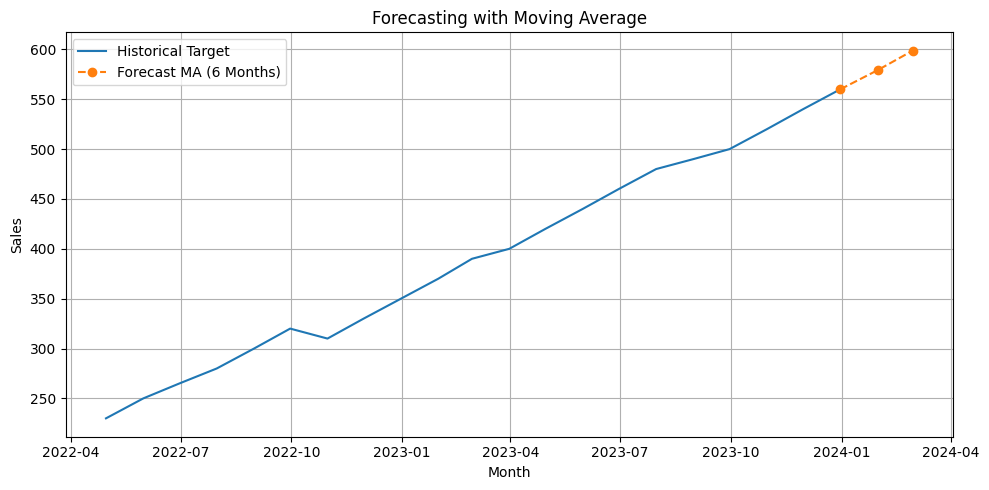

In [21]:
# Buat index tanggal untuk prediksi ke depan
last_date = df_ml.index[-1]
future_dates = pd.date_range(start=last_date + pd.DateOffset(months=1), periods=n_future, freq='ME')

# Gabungkan titik terakhir dari data historis agar garis tidak terputus
joined_dates = [last_date] + list(future_dates)
joined_values = [df_ml['target'].iloc[-1]] + forecast_future

plt.figure(figsize=(10, 5))
plt.plot(df_ml.index, df_ml['target'], label='Historical Target')
plt.plot(joined_dates, joined_values, label='Forecast MA (6 Months)', linestyle='--', marker='o')
plt.title('Forecasting with Moving Average')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
